In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/vehicle-type-classification/vehicle_train_10000.csv
/kaggle/input/competitions/vehicle-type-classification/vehicle_test.csv
/kaggle/input/competitions/vehicle-type-classification/vehicle_sample_submission.csv


# Multiclass Vehicle Classification Using Machine Learning

**Machine Learning Coursework and Viva Portfolio**

## Problem Statement

The objective is to classify each vehicle into one of three categories—Sedan (Class 0), SUV (Class 1), or Sports Car (Class 2)—using its physical and performance-related attributes.

## Objectives

1. Explore the dataset, examine class balance, inspect feature distributions, and identify duplicate records and highly correlated features.
2. Engineer domain-informed physical ratios and evaluate whether they improve classification performance.
3. Compare probabilistic classifiers, a decision tree, Logistic Regression, Random Forest, and XGBoost.
4. Evaluate models using stratified five-fold cross-validation and compare their predictive performance.
5. Select a final model and generate predictions for the competition test dataset.

## Experimental Approach

The experiments compare raw features with alternative feature representations and examine the effect of model choice and regularization. The final model is a blend of Logistic Regression and XGBoost using the original 20 features. An additional engineered-feature experiment is retained for comparison.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing and evaluation
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Core classifiers
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Visualization styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

SEED = 42
np.random.seed(SEED)

## Section 1: Exploratory Data Analysis

This section examines the dataset's dimensions, target-class distribution, missing values, duplicate feature combinations, summary statistics, feature distributions, potential outliers, and pairwise correlations. The findings help guide preprocessing and the subsequent model comparisons.

In [3]:
TRAIN_PATH = '/kaggle/input/competitions/vehicle-type-classification/vehicle_train_10000.csv'
TEST_PATH  = '/kaggle/input/competitions/vehicle-type-classification/vehicle_test.csv'

df_train_raw = pd.read_csv(TRAIN_PATH)
df_test      = pd.read_csv(TEST_PATH)

target_col = 'vehicle_class'
id_col = 'vehicle_id'
feature_cols = [c for c in df_train_raw.columns if c not in [id_col, target_col]]
class_labels = {0: 'Sedan', 1: 'SUV', 2: 'Sports Car'}

print("=" * 65)
print(f"RAW TRAIN SHAPE : {df_train_raw.shape[0]:,} rows, {df_train_raw.shape[1]} columns")
print(f"RAW TEST SHAPE  : {df_test.shape[0]:,} rows, {df_test.shape[1]} columns")
print("=" * 65)

# 1. Target Class Balance
class_counts = df_train_raw[target_col].value_counts().sort_index()
class_pcts = df_train_raw[target_col].value_counts(normalize=True).sort_index() * 100

target_dist = pd.DataFrame({
    'Class Index': class_counts.index,
    'Class Name': [class_labels[i] for i in class_counts.index],
    'Count': class_counts.values,
    'Proportion (%)': class_pcts.round(2).values
})
print("\n--- Target Class Balance Check ---")
print(target_dist.to_string(index=False))

# 2. Missing Value Audit
missing_series = df_train_raw.isnull().sum()
print("\n--- Missing Values Check ---")
if missing_series.sum() == 0:
    print("Zero missing values detected across all columns.")
else:
    print(missing_series[missing_series > 0])

RAW TRAIN SHAPE : 10,000 rows, 22 columns
RAW TEST SHAPE  : 2,500 rows, 21 columns

--- Target Class Balance Check ---
 Class Index Class Name  Count  Proportion (%)
           0      Sedan   3389           33.89
           1        SUV   3326           33.26
           2 Sports Car   3285           32.85

--- Missing Values Check ---
Zero missing values detected across all columns.


In [4]:
# 1. Five-Number Summary
print("--- Five-Number Summary Statistics ---")
desc_stats = df_train_raw[feature_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
pd.set_option('display.max_rows', 30)
pd.set_option('display.width', 1000)
print(desc_stats.round(2))

# 2. Deduplication Audit
dup_count = df_train_raw.duplicated(subset=feature_cols).sum()
print("\n" + "=" * 65)
print(f"DUPLICATE FEATURE ROWS DETECTED : {dup_count} (out of {len(df_train_raw)} rows)")
df_clean = df_train_raw.drop_duplicates(subset=feature_cols).reset_index(drop=True)
print(f"CLEAN UNIQUE DATASET SIZE       : {len(df_clean)} rows")
print("=" * 65)

# 3. Tukey's IQR Outlier Profiling
outlier_summary = []
for col in feature_cols:
    vals = df_clean[col]
    q1 = vals.quantile(0.25)
    q3 = vals.quantile(0.75)
    iqr = q3 - q1
    lower_b = q1 - 1.5 * iqr
    upper_b = q3 + 1.5 * iqr
    num_outliers = ((vals < lower_b) | (vals > upper_b)).sum()
    
    outlier_summary.append({
        'Feature': col,
        'Q1': round(q1, 2),
        'Q3': round(q3, 2),
        'IQR': round(iqr, 2),
        'Lower Bound': round(lower_b, 2),
        'Upper Bound': round(upper_b, 2),
        'Outliers': num_outliers,
        'Outlier %': round((num_outliers / len(df_clean)) * 100, 2)
    })

outlier_table = pd.DataFrame(outlier_summary)
print("\n--- Features Containing IQR Outliers ---")
print(outlier_table[outlier_table['Outliers'] > 0].to_string(index=False))

--- Five-Number Summary Statistics ---
                                count     mean     std      min      25%      50%      75%      max
engine_displacement_l         10000.0     2.43    0.61     0.90     2.00     2.43     2.85     4.44
horsepower_hp                 10000.0   296.50   95.56    90.00   226.00   294.00   364.00   550.00
vehicle_weight_kg             10000.0  1636.40  306.18  1100.00  1409.00  1604.00  1852.00  2600.00
wheelbase_mm                  10000.0  2778.06  172.35  2400.00  2651.00  2756.00  2906.00  3300.00
vehicle_length_mm             10000.0  4660.04  366.06  3900.00  4387.75  4622.00  4937.00  5400.00
vehicle_width_mm              10000.0  1836.67  117.74  1650.00  1744.00  1824.00  1928.00  2050.00
vehicle_height_mm             10000.0  1528.94  145.98  1250.00  1423.00  1530.00  1634.00  2050.00
fuel_tank_capacity_l          10000.0    61.10   14.51    35.00    50.00    60.00    72.00    90.00
city_fuel_efficiency_kmpl     10000.0    11.61    2.57     7.

In [40]:

# ============================================================
# DUPLICATE AUDIT: IDENTICAL FEATURES, SAME OR DIFFERENT LABELS
# ============================================================

import pandas as pd

# 1. Group rows that have identical feature values
duplicate_summary = (
    df_train_raw
    .groupby(feature_cols, dropna=False, sort=False)[target_col]
    .agg(
        row_count="size",
        unique_label_count=lambda s: s.nunique(dropna=False),
        labels=lambda s: sorted(s.astype(str).unique().tolist())
    )
    .reset_index()
)

# Keep only groups containing duplicate feature combinations
duplicate_groups = duplicate_summary[
    duplicate_summary["row_count"] > 1
].copy()

# 2. Separate consistent duplicates from conflicting duplicates
consistent_duplicates = duplicate_groups[
    duplicate_groups["unique_label_count"] == 1
].copy()

conflicting_duplicates = duplicate_groups[
    duplicate_groups["unique_label_count"] > 1
].copy()

# 3. Print summary
print("=" * 75)
print("DUPLICATE FEATURE AUDIT")
print("=" * 75)

print(f"Original training rows       : {len(df_train_raw)}")
print(f"Duplicate feature groups     : {len(duplicate_groups)}")
print(f"Groups with same label       : {len(consistent_duplicates)}")
print(f"Groups with different labels : {len(conflicting_duplicates)}")

print(f"\nRows in conflicting groups  : "
      f"{conflicting_duplicates['row_count'].sum()}")

print("=" * 75)

# 4. Display the conflicting feature combinations
if conflicting_duplicates.empty:
    print("\nNo conflicting duplicate groups found.")
else:
    print("\nCONFLICTING DUPLICATE GROUPS:")
    display(
        conflicting_duplicates.sort_values(
            "row_count", ascending=False
        )
    )

# 5. Show the original rows in those conflicting groups
# This makes it easy to compare vehicle IDs and target labels.
conflict_mask = (
    df_train_raw
    .groupby(feature_cols, dropna=False, sort=False)[target_col]
    .transform(lambda s: s.nunique(dropna=False))
    .gt(1)
)

conflicting_rows = df_train_raw.loc[conflict_mask].copy()

if not conflicting_rows.empty:
    print("\nALL ORIGINAL ROWS WITH CONFLICTING LABELS:")

    columns_to_show = (
        ([id_col] if id_col in df_train_raw.columns else [])
        + feature_cols
        + [target_col]
    )

    display(
        conflicting_rows[columns_to_show]
        .sort_values(feature_cols, kind="stable")
        .reset_index(drop=True)
    )

# 6. Optional: save the audit results
conflicting_duplicates.to_csv(
    "conflicting_duplicate_groups.csv", index=False
)
conflicting_rows.to_csv(
    "conflicting_duplicate_rows.csv", index=False
)

print("\nSaved:")
print(" - conflicting_duplicate_groups.csv")
print(" - conflicting_duplicate_rows.csv")


DUPLICATE FEATURE AUDIT
Original training rows       : 10000
Duplicate feature groups     : 2500
Groups with same label       : 2500
Groups with different labels : 0

Rows in conflicting groups  : 0

No conflicting duplicate groups found.

Saved:
 - conflicting_duplicate_groups.csv
 - conflicting_duplicate_rows.csv


### Feature Distributions and Skewness

Skewness measures the asymmetry of a feature's distribution. Histograms and class-conditioned boxplots help reveal distribution shapes, potential outliers, and differences between vehicle classes.

The observed skewness values are generally close to zero, suggesting limited univariate asymmetry in these features. Standardization is used for models such as Logistic Regression, where feature scales can affect optimization. Scaling is not a requirement for tree-based models, which use feature-based split thresholds.

In [18]:
# 1. Check feature balance (skewness)
skew_values = df_clean[feature_cols].skew().round(2)

skew_summary = pd.DataFrame({
    'Feature': skew_values.index,
    'Skewness': skew_values.values
}).sort_values(by='Skewness', ascending=False)

print("--- Feature Skewness (Values close to 0 are well-balanced) ---")
print(skew_summary.to_string(index=False))

--- Feature Skewness (Values close to 0 are well-balanced) ---
                     Feature  Skewness
         ground_clearance_mm      0.48
           vehicle_weight_kg      0.34
            cargo_capacity_l      0.32
                wheelbase_mm      0.29
        battery_capacity_kwh      0.29
            vehicle_width_mm      0.25
   city_fuel_efficiency_kmpl      0.22
           vehicle_length_mm      0.20
        fuel_tank_capacity_l      0.18
          braking_distance_m      0.17
               horsepower_hp      0.12
            engine_cylinders      0.10
           vehicle_height_mm      0.09
            drag_coefficient      0.06
highway_fuel_efficiency_kmpl      0.03
                   torque_nm      0.01
       engine_displacement_l     -0.00
            turning_radius_m     -0.00
    acceleration_0_100_kmh_s     -0.09
               tire_width_mm     -0.10


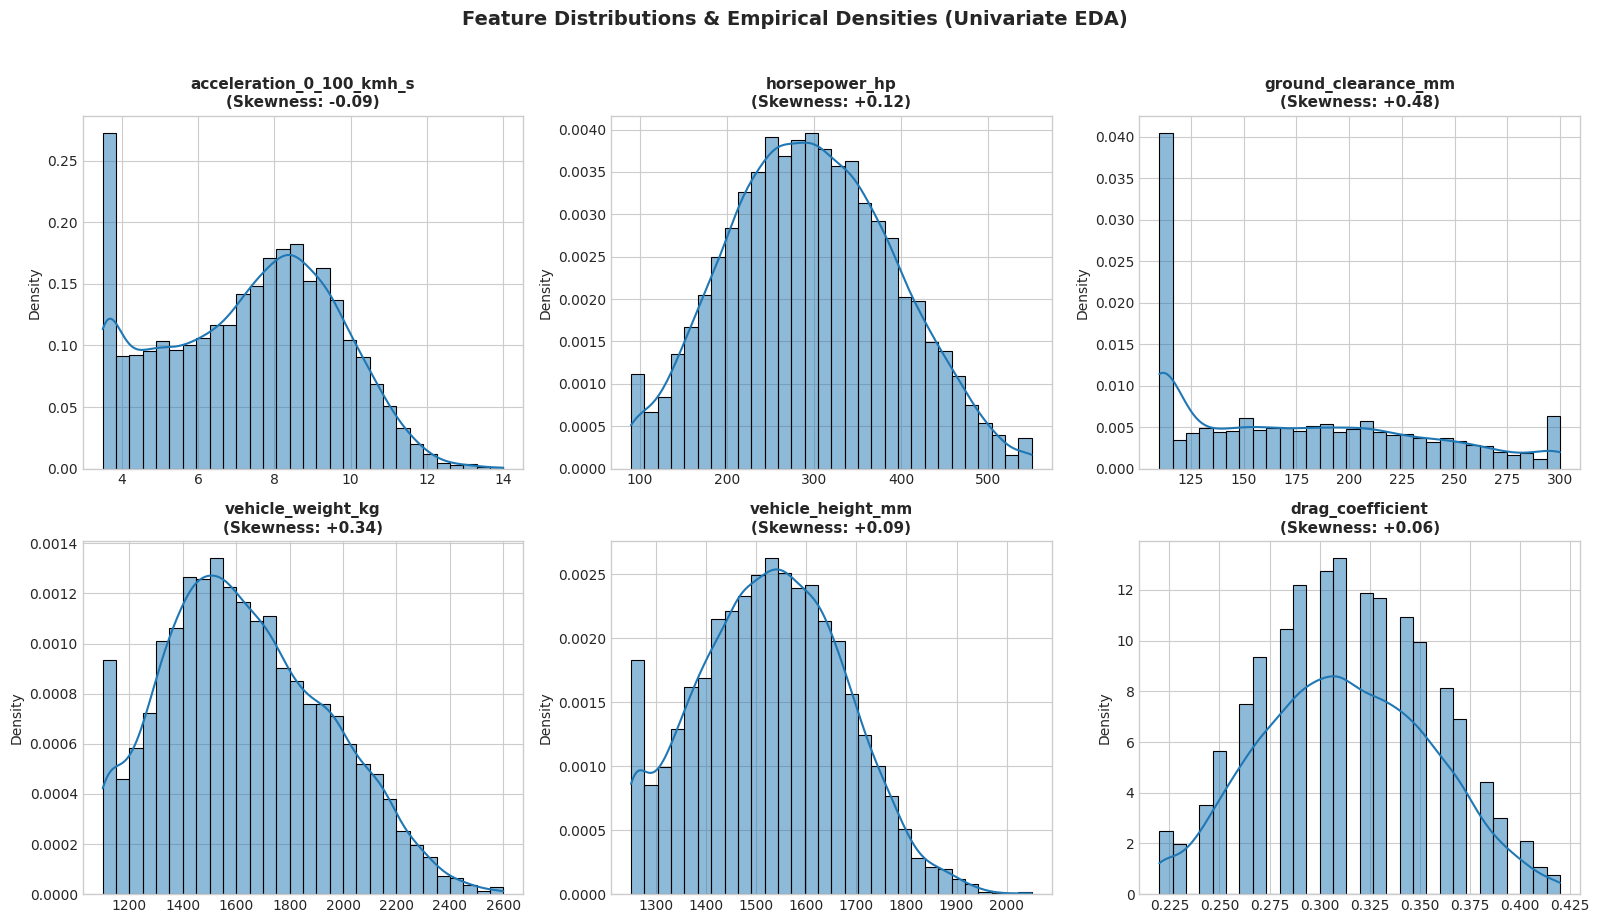

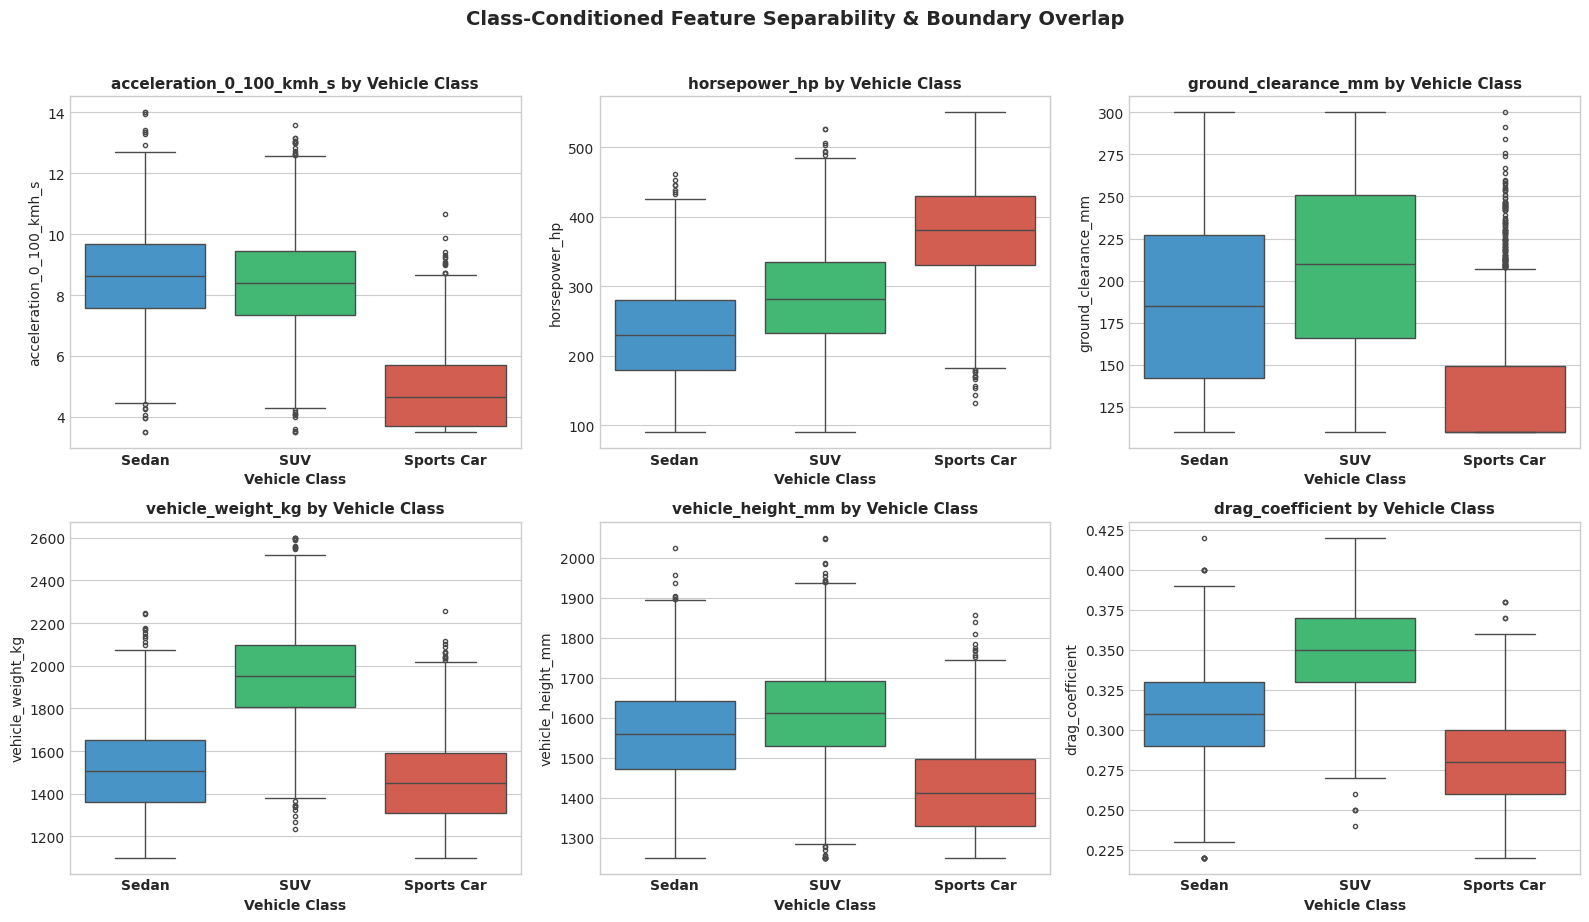

In [21]:
import warnings
warnings.filterwarnings('ignore')

# 1. Distribution Histograms with Kernel Density Estimation (KDE)
# Plotting the 6 most critical physical dynamic & dimension attributes
key_features = [
    'acceleration_0_100_kmh_s',
    'horsepower_hp',
    'ground_clearance_mm',
    'vehicle_weight_kg',
    'vehicle_height_mm',
    'drag_coefficient'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(key_features):
    sns.histplot(
        data=df_clean,
        x=col,
        kde=True,
        color='#1f77b4',
        bins=30,
        ax=axes[i],
        stat='density'
    )
    axes[i].set_title(f"{col}\n(Skewness: {df_clean[col].skew():+.2f})", fontsize=11, weight='bold')
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Density")

plt.suptitle("Feature Distributions & Empirical Densities (Univariate EDA)", fontsize=14, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 2. Class-Conditioned Boxplots: Visualizing Separability Across Classes
# Maps how Sedan (0), SUV (1), and Sports Car (2) separate along physical axes
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
palette_colors = {0: '#3498db', 1: '#2ecc71', 2: '#e74c3c'}  # Blue: Sedan, Green: SUV, Red: Sports Car

unique_classes = sorted(df_clean[target_col].unique())
class_names = [class_labels[c] for c in unique_classes]

for i, col in enumerate(key_features):
    sns.boxplot(
        data=df_clean,
        x=target_col,
        y=col,
        hue=target_col,
        palette=palette_colors,
        legend=False,
        ax=axes[i],
        fliersize=3
    )
    axes[i].set_xticks(range(len(unique_classes)))
    axes[i].set_xticklabels(class_names, weight='bold')
    axes[i].set_title(f"{col} by Vehicle Class", fontsize=11, weight='bold')
    axes[i].set_xlabel("Vehicle Class", weight='bold')
    axes[i].set_ylabel(col)

plt.suptitle("Class-Conditioned Feature Separability & Boundary Overlap", fontsize=14, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

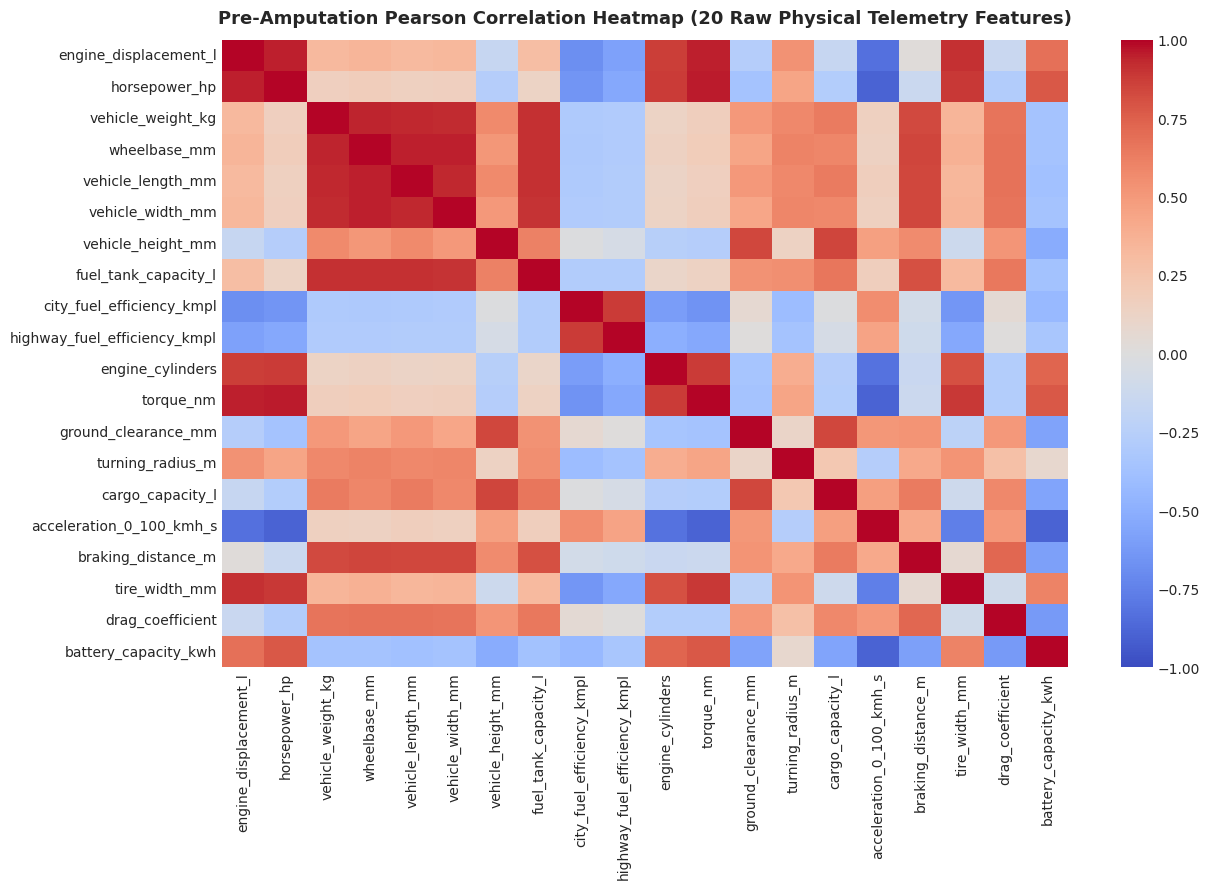


--- Severe Collinearity Pairs (|r| > 0.85) ---
                Feature 1                    Feature 2  Pearson r
            horsepower_hp                    torque_nm      0.959
    engine_displacement_l                    torque_nm      0.952
             wheelbase_mm             vehicle_width_mm      0.952
    engine_displacement_l                horsepower_hp      0.950
             wheelbase_mm            vehicle_length_mm      0.949
        vehicle_weight_kg                 wheelbase_mm      0.945
        vehicle_length_mm             vehicle_width_mm      0.937
        vehicle_weight_kg            vehicle_length_mm      0.935
        vehicle_weight_kg             vehicle_width_mm      0.929
        vehicle_length_mm         fuel_tank_capacity_l      0.914
             wheelbase_mm         fuel_tank_capacity_l      0.912
    engine_displacement_l                tire_width_mm      0.912
        vehicle_weight_kg         fuel_tank_capacity_l      0.907
         vehicle_width_mm   

In [5]:
corr_matrix_raw = df_clean[feature_cols].corr()

plt.figure(figsize=(13, 9))
sns.heatmap(corr_matrix_raw, cmap='coolwarm', vmin=-1, vmax=1, annot=False)
plt.title("Pre-Amputation Pearson Correlation Heatmap (20 Raw Physical Telemetry Features)", fontsize=13, weight='bold', pad=12)
plt.tight_layout()
plt.show()

# Extract Pairs with |r| > 0.85
upper_tri = corr_matrix_raw.where(np.triu(np.ones(corr_matrix_raw.shape), k=1).astype(bool))
high_corr = upper_tri.stack().reset_index()
high_corr.columns = ['Feature 1', 'Feature 2', 'Pearson r']
high_corr = high_corr[high_corr['Pearson r'].abs() > 0.85].sort_values(by='Pearson r', ascending=False)

print("\n--- Severe Collinearity Pairs (|r| > 0.85) ---")
print(high_corr.round(3).to_string(index=False))

## Section 2: Feature Engineering and Correlation-Based Feature Selection

### 2.1 Domain-Informed Feature Engineering

Five additional features are constructed from vehicle attributes:

- **Power-to-weight ratio:** horsepower divided by vehicle weight.
- **Torque-to-weight ratio:** torque divided by vehicle weight.
- **Height-to-width ratio:** vehicle height divided by vehicle width.
- **Ground-clearance ratio:** ground clearance divided by vehicle height.
- **Estimated volume:** vehicle length multiplied by width and height, converted from cubic millimetres to cubic metres.

Small constants are added to the denominators of the ratios to avoid division by zero.

### 2.2 Correlation-Based Feature Selection

Pearson correlations are used to identify highly correlated feature pairs. A threshold of |r| > 0.85 is used in a greedy procedure to remove redundant features from the engineered feature matrix.

This procedure is an exploratory feature-selection experiment. Correlation does not necessarily imply that a feature is unhelpful for classification, so the resulting feature set is evaluated empirically rather than assumed to be better.

Features after engineering: 25 (20 raw + 5 physical ratios)

--- Feature Amputation Summary ---
Amputated (Dropped) Features Count: 16
Amputated Columns:                  ['horsepower_hp', 'wheelbase_mm', 'vehicle_length_mm', 'vehicle_width_mm', 'fuel_tank_capacity_l', 'highway_fuel_efficiency_kmpl', 'engine_cylinders', 'torque_nm', 'acceleration_0_100_kmh_s', 'braking_distance_m', 'tire_width_mm', 'battery_capacity_kwh', 'power_to_weight', 'torque_to_weight', 'clearance_ratio', 'volume_est_m3']
Retained Features Count:            9


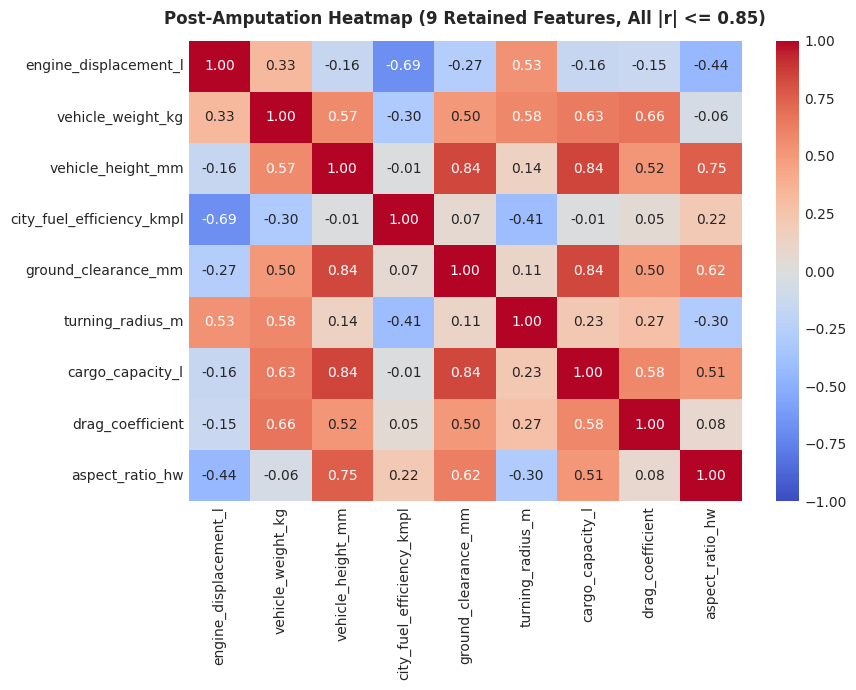

In [7]:
# 1. Physical Ratio Engineering
def engineer_physics_ratios(df):
    df_out = df.copy()
    df_out['power_to_weight'] = df_out['horsepower_hp'] / (df_out['vehicle_weight_kg'] + 1e-5)
    df_out['torque_to_weight'] = df_out['torque_nm'] / (df_out['vehicle_weight_kg'] + 1e-5)
    df_out['aspect_ratio_hw'] = df_out['vehicle_height_mm'] / (df_out['vehicle_width_mm'] + 1e-5)
    df_out['clearance_ratio'] = df_out['ground_clearance_mm'] / (df_out['vehicle_height_mm'] + 1e-5)
    df_out['volume_est_m3'] = (df_out['vehicle_length_mm'] * df_out['vehicle_width_mm'] * df_out['vehicle_height_mm']) / 1e9
    return df_out

X_all_df = engineer_physics_ratios(df_clean[feature_cols])
print(f"Features after engineering: {X_all_df.shape[1]} (20 raw + 5 physical ratios)")

# 2. Collinearity Amputation (|r| > 0.85)
def amputate_collinear_features(df, threshold=0.85):
    corr = df.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    dropped = [col for col in upper.columns if any(upper[col] > threshold)]
    return df.drop(columns=dropped), dropped

X_amputated_df, amputated_cols = amputate_collinear_features(X_all_df, threshold=0.85)
X_raw_df = df_clean[feature_cols].copy()

print("\n--- Feature Amputation Summary ---")
print(f"Amputated (Dropped) Features Count: {len(amputated_cols)}")
print(f"Amputated Columns:                  {amputated_cols}")
print(f"Retained Features Count:            {X_amputated_df.shape[1]}")

# 3. Post-Amputation Correlation Heatmap
corr_matrix_amp = X_amputated_df.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix_amp, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.2f', cbar=True)
plt.title(f"Post-Amputation Heatmap ({X_amputated_df.shape[1]} Retained Features, All |r| <= 0.85)", fontsize=12, weight='bold', pad=12)
plt.tight_layout()
plt.show()

## Section 3: Probabilistic Classifiers — QDA and Gaussian Naive Bayes

### Quadratic Discriminant Analysis (QDA)

QDA models the feature distribution within each class using a multivariate Gaussian distribution with a separate covariance matrix for each class. This permits quadratic decision boundaries.

### Gaussian Naive Bayes (GNB)

Gaussian Naive Bayes models each feature's class-conditional distribution as Gaussian and assumes that the features are conditionally independent given the class. This simplifies estimation but may be restrictive when features are correlated.

Both classifiers are evaluated using the original and correlation-filtered feature matrices. Their cross-validation results illustrate how the model assumptions and feature representation affect classification performance.

In [8]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
y_clean = df_clean[target_col].values

# Leak-free Cross-Validation Helper
def evaluate_cv(estimator, X_mat, y_vec, scale=True):
    oof_preds = np.zeros(len(y_vec), dtype=int)
    train_scores = []
    
    for tr_idx, va_idx in skf.split(X_mat, y_vec):
        X_tr, y_tr = X_mat[tr_idx], y_vec[tr_idx]
        X_va, y_va = X_mat[va_idx], y_vec[va_idx]
        
        steps = [('imputer', SimpleImputer(strategy='median'))]
        if scale:
            steps.append(('scaler', StandardScaler()))
        steps.append(('clf', estimator))
        
        pipe = Pipeline(steps)
        pipe.fit(X_tr, y_tr)
        
        train_scores.append(accuracy_score(y_tr, pipe.predict(X_tr)))
        oof_preds[va_idx] = pipe.predict(X_va)
        
    mean_train_acc = float(np.mean(train_scores))
    val_acc = accuracy_score(y_vec, oof_preds)
    return mean_train_acc, val_acc, oof_preds

# 1. Full Bayes (QDA)
train_fb_raw, acc_fb_raw, oof_fb_raw = evaluate_cv(QuadraticDiscriminantAnalysis(reg_param=1e-2), X_raw_df.values, y_clean)
train_fb_amp, acc_fb_amp, _           = evaluate_cv(QuadraticDiscriminantAnalysis(reg_param=1e-2), X_amputated_df.values, y_clean)

# 2. Gaussian Naive Bayes (GNB)
train_gnb_raw, acc_gnb_raw, oof_gnb_raw = evaluate_cv(GaussianNB(var_smoothing=1e-2), X_raw_df.values, y_clean)
train_gnb_amp, acc_gnb_amp, _           = evaluate_cv(GaussianNB(var_smoothing=1e-2), X_amputated_df.values, y_clean)

# Summary Table
bayes_comparison_df = pd.DataFrame({
    'Generative Architecture': [
        'Full Gaussian Bayes (QDA, Raw)',
        'Full Gaussian Bayes (QDA, Amputated)',
        'Gaussian Naive Bayes (GNB, Raw)',
        'Gaussian Naive Bayes (GNB, Amputated)'
    ],
    'Train Accuracy': [f"{train_fb_raw*100:.2f}%", f"{train_fb_amp*100:.2f}%", f"{train_gnb_raw*100:.2f}%", f"{train_gnb_amp*100:.2f}%"],
    '5-Fold CV Accuracy': [f"{acc_fb_raw*100:.2f}%", f"{acc_fb_amp*100:.2f}%", f"{acc_gnb_raw*100:.2f}%", f"{acc_gnb_amp*100:.2f}%"],
    'Generalization Gap': [
        f"{(train_fb_raw - acc_fb_raw)*100:+.2f}%",
        f"{(train_fb_amp - acc_fb_amp)*100:+.2f}%",
        f"{(train_gnb_raw - acc_gnb_raw)*100:+.2f}%",
        f"{(train_gnb_amp - acc_gnb_amp)*100:+.2f}%"
    ]
})

print("=" * 80)
print("GENERATIVE BENCHMARK: FULL BAYES (QDA) VS NAIVE BAYES (GNB)")
print("=" * 80)
print(bayes_comparison_df.to_string(index=False))

GENERATIVE BENCHMARK: FULL BAYES (QDA) VS NAIVE BAYES (GNB)
              Generative Architecture Train Accuracy 5-Fold CV Accuracy Generalization Gap
       Full Gaussian Bayes (QDA, Raw)         89.42%             88.67%             +0.75%
 Full Gaussian Bayes (QDA, Amputated)         86.71%             86.59%             +0.12%
      Gaussian Naive Bayes (GNB, Raw)         84.70%             84.72%             -0.02%
Gaussian Naive Bayes (GNB, Amputated)         77.88%             77.83%             +0.05%


## Section 4: Decision Tree Classification

A decision tree recursively partitions the feature space using thresholds on individual features. It can model nonlinear relationships and feature interactions, but a deep tree may overfit the training data.
Several maximum-depth values were evaluated using stratified five-fold cross-validation. 
A depth of 8 was retained for the subsequent benchmark comparison, although depth 5 achieved the highest CV accuracy in the tested sweep. Therefore, the depth-8 model is a comparison configuration rather than the best-performing depth from this experiment.

In [49]:
tree_depths = [3, 5, 8, 12, 16, None]
tree_results = {}
tree_train_results = {}

print("--- Decision Tree Hyperparameter Sweep (max_depth) ---")
for d in tree_depths:
    d_label = str(d) if d is not None else "None (Unconstrained)"
    tr_acc, val_acc, _ = evaluate_cv(
        DecisionTreeClassifier(max_depth=d, min_samples_leaf=5, random_state=SEED),
        X_raw_df.values, y_clean, scale=False # Trees are scale-invariant
    )
    tree_results[d_label] = val_acc
    tree_train_results[d_label] = tr_acc
    print(f"max_depth = {d_label:<18} | Train Acc: {tr_acc*100:>5.2f}% | 5-Fold CV: {val_acc*100:>5.2f}% | Gap: {(tr_acc - val_acc)*100:>+5.2f}%")

best_depth_label = max(tree_results, key=tree_results.get)
best_dt_train_acc, best_dt_acc, oof_dt_best = evaluate_cv(
    DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=SEED),
    X_raw_df.values, y_clean, scale=False
)
print(
    f"\nDecision Tree (fixed max_depth=8): "
    f"Train {best_dt_train_acc*100:.2f}% | "
    f"5-Fold CV {best_dt_acc*100:.2f}%"
)

--- Decision Tree Hyperparameter Sweep (max_depth) ---
max_depth = 3                  | Train Acc: 85.61% | 5-Fold CV: 84.92% | Gap: +0.69%
max_depth = 5                  | Train Acc: 88.34% | 5-Fold CV: 86.36% | Gap: +1.98%
max_depth = 8                  | Train Acc: 91.61% | 5-Fold CV: 85.64% | Gap: +5.97%
max_depth = 12                 | Train Acc: 93.94% | 5-Fold CV: 84.64% | Gap: +9.30%
max_depth = 16                 | Train Acc: 94.13% | 5-Fold CV: 84.20% | Gap: +9.93%
max_depth = None (Unconstrained) | Train Acc: 94.15% | 5-Fold CV: 84.00% | Gap: +10.15%

Decision Tree (fixed max_depth=8): Train 91.61% | 5-Fold CV 85.64%


## Section 5: Discriminative Linear Modeling — Multinomial Logistic Regression

Multinomial Logistic Regression models class posteriors via linear logits through the Softmax function:
$$P(Y = k \mid \mathbf{x}) = \frac{e^{\mathbf{w}_k^T \mathbf{x} + b_k}}{\sum_{j=0}^2 e^{\mathbf{w}_j^T \mathbf{x} + b_j}}$$

Multinomial Logistic Regression estimates class probabilities using the softmax function applied to class-specific linear scores. An L2 regularization penalty discourages excessively large coefficients and can help control overfitting.

The inverse regularization parameter, C, is evaluated over a predefined grid using stratified five-fold cross-validation. The value with the highest observed cross-validation accuracy is selected for subsequent experiments.

A NumPy implementation is also included to demonstrate the underlying softmax probability calculation and gradient-based parameter updates. Its reported training accuracy is an implementation check, not an independent validation result.

In [12]:
# 1. Regularization Strength (C) Sweep
c_values = [0.001, 0.01, 0.1, 1.0, 10.0]
lr_results = {}
lr_train_results = {}

print("--- Tuning Regularization Strength (C) for Logistic Regression ---")
for c in c_values:
    tr_acc, val_acc, _ = evaluate_cv(
        LogisticRegression(C=c, max_iter=1500, solver='lbfgs', random_state=SEED),
        X_raw_df.values, y_clean, scale=True
    )
    lr_results[c] = val_acc
    lr_train_results[c] = tr_acc
    print(f"C = {c:<6} | Train Acc: {tr_acc*100:>5.2f}% | 5-Fold CV: {val_acc*100:>5.2f}% | Gap: {(tr_acc - val_acc)*100:>+5.2f}%")

best_c = max(lr_results, key=lr_results.get)
best_lr_train_acc, best_lr_acc, oof_lr_best = evaluate_cv(
    LogisticRegression(C=best_c, max_iter=1500, solver='lbfgs', random_state=SEED),
    X_raw_df.values, y_clean, scale=True
)
print(f"\nOptimal Logistic Regression (C={best_c}): Train {best_lr_train_acc*100:.2f}% | 5-Fold CV {best_lr_acc*100:.2f}%")

# 2. Mathematical Scratch NumPy Implementation
class ScratchMultinomialLogisticRegression:
    def __init__(self, lr=0.15, reg_lambda=0.01, epochs=700):
        self.lr = lr
        self.reg_lambda = reg_lambda
        self.epochs = epochs

    def _softmax(self, Z):
        exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    def fit(self, X, y, num_classes=3):
        N, D = X.shape
        Y_one_hot = np.zeros((N, num_classes))
        Y_one_hot[np.arange(N), y] = 1.0
        self.W = np.zeros((D, num_classes))
        self.b = np.zeros((1, num_classes))

        for _ in range(self.epochs):
            Z = np.dot(X, self.W) + self.b
            P = self._softmax(Z)
            error = P - Y_one_hot
            dW = (1.0 / N) * np.dot(X.T, error) + self.reg_lambda * self.W
            db = (1.0 / N) * np.sum(error, axis=0, keepdims=True)
            self.W -= self.lr * dW
            self.b -= self.lr * db

    def predict(self, X):
        Z = np.dot(X, self.W) + self.b
        return np.argmax(self._softmax(Z), axis=1)

scaler_scratch = StandardScaler()
X_sc_scaled = scaler_scratch.fit_transform(X_raw_df.values)
scratch_model = ScratchMultinomialLogisticRegression(lr=0.15, reg_lambda=0.01, epochs=700)
scratch_model.fit(X_sc_scaled, y_clean)
scratch_train_acc = accuracy_score(y_clean, scratch_model.predict(X_sc_scaled))
print(f"Scratch NumPy Softmax Regression Train Accuracy: {scratch_train_acc*100:.2f}%")

--- Tuning Regularization Strength (C) for Logistic Regression ---
C = 0.001  | Train Acc: 86.93% | 5-Fold CV: 86.95% | Gap: -0.01%
C = 0.01   | Train Acc: 89.14% | 5-Fold CV: 89.09% | Gap: +0.04%
C = 0.1    | Train Acc: 89.60% | 5-Fold CV: 89.41% | Gap: +0.18%
C = 1.0    | Train Acc: 89.54% | 5-Fold CV: 89.41% | Gap: +0.13%
C = 10.0   | Train Acc: 89.51% | 5-Fold CV: 89.40% | Gap: +0.11%

Optimal Logistic Regression (C=0.1): Train 89.60% | 5-Fold CV 89.41%
Scratch NumPy Softmax Regression Train Accuracy: 89.43%


In [30]:
# -------------------------------------------------------------------------
# Feature Matrix Comparison: Raw vs Imputed vs Engineered under Logistic Regression
# -------------------------------------------------------------------------
print("=" * 80)
print("FEATURE MATRIX COMPARISON (LOGISTIC REGRESSION, C=0.10)")
print("=" * 80)

# Build candidate feature matrices safely from your notebook scope
matrix_candidates = {
    'Imputed Matrix (20 feats)': SimpleImputer(strategy='median').fit_transform(df_clean[feature_cols].values),
}

# Safely include engineered or amputated matrices if they exist in your workspace
if 'X_all_df' in globals():
    matrix_candidates['Engineered Physics (25 feats)'] = X_all_df.values
if 'X_compact_df' in globals():
    matrix_candidates['Compact Engineered (21 feats)'] = X_compact_df.values
if 'X_amputated_df' in globals():
    matrix_candidates['Amputated |r|<0.85 (9 feats)'] = X_amputated_df.values

matrix_comparison_rows = []
for matrix_name, mat_val in matrix_candidates.items():
    tr_acc, val_acc, _ = evaluate_cv(
        LogisticRegression(C=0.10, max_iter=2000, solver='lbfgs', random_state=SEED),
        mat_val, df_clean[target_col].values, scale=True
    )
    matrix_comparison_rows.append({
        'Feature Representation': matrix_name,
        'Train Accuracy': f"{tr_acc * 100:.2f}%",
        '5-Fold CV Accuracy': f"{val_acc * 100:.2f}%",
        'Generalization Gap': f"{(tr_acc - val_acc) * 100:+.2f}%"
    })

matrix_df = pd.DataFrame(matrix_comparison_rows)
print(matrix_df.to_string(index=False))
print("=" * 80)

FEATURE MATRIX COMPARISON (LOGISTIC REGRESSION, C=0.10)
       Feature Representation Train Accuracy 5-Fold CV Accuracy Generalization Gap
    Imputed Matrix (20 feats)         89.60%             89.41%             +0.18%
Engineered Physics (25 feats)         89.60%             89.48%             +0.12%
 Amputated |r|<0.85 (9 feats)         86.70%             86.48%             +0.22%


CORE MODEL BENCHMARK (7,500 UNIQUE ROWS)
                     Model Architecture Train Accuracy 5-Fold CV Accuracy Generalization Gap
             Gaussian Naive Bayes (Raw)         84.70%             84.72%             -0.02%
         Full Gaussian Bayes (QDA, Raw)         89.42%             88.67%             +0.75%
     Single Decision Tree (max_depth=8)         91.61%             85.64%             +5.97%
Multinomial Logistic Regression (C=0.1)         89.60%             89.41%             +0.18%


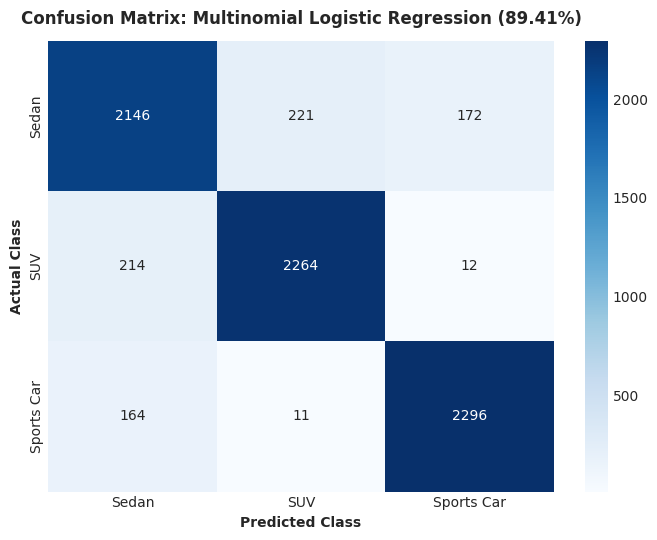


--- Detailed Classification Metrics ---
              precision    recall  f1-score   support

       Sedan     0.8502    0.8452    0.8477      2539
         SUV     0.9071    0.9092    0.9081      2490
  Sports Car     0.9258    0.9292    0.9275      2471

    accuracy                         0.8941      7500
   macro avg     0.8944    0.8945    0.8945      7500
weighted avg     0.8940    0.8941    0.8941      7500



In [24]:
# 1. Comparative Benchmark Table
benchmark_df = pd.DataFrame({
    'Model Architecture': [
        'Gaussian Naive Bayes (Raw)',
        'Full Gaussian Bayes (QDA, Raw)',
        'Single Decision Tree (max_depth=8)',
        f'Multinomial Logistic Regression (C={best_c})'
    ],
    'Train Accuracy': [f"{train_gnb_raw*100:.2f}%", f"{train_fb_raw*100:.2f}%", f"{best_dt_train_acc*100:.2f}%", f"{best_lr_train_acc*100:.2f}%"],
    '5-Fold CV Accuracy': [f"{acc_gnb_raw*100:.2f}%", f"{acc_fb_raw*100:.2f}%", f"{best_dt_acc*100:.2f}%", f"{best_lr_acc*100:.2f}%"],
    'Generalization Gap': [
        f"{(train_gnb_raw - acc_gnb_raw)*100:+.2f}%",
        f"{(train_fb_raw - acc_fb_raw)*100:+.2f}%",
        f"{(best_dt_train_acc - best_dt_acc)*100:+.2f}%",
        f"{(best_lr_train_acc - best_lr_acc)*100:+.2f}%"
    ]
})

print("=" * 88)
print("CORE MODEL BENCHMARK (7,500 UNIQUE ROWS)")
print("=" * 88)
print(benchmark_df.to_string(index=False))

# 2. Confusion Matrix of Logistic Regression
cm = confusion_matrix(y_clean, oof_lr_best)
cm_labels = [class_labels[i] for i in range(3)]

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=cm_labels, yticklabels=cm_labels)
plt.title(f"Confusion Matrix: Multinomial Logistic Regression ({best_lr_acc*100:.2f}%)", weight='bold', pad=12)
plt.xlabel("Predicted Class", weight='bold')
plt.ylabel("Actual Class", weight='bold')
plt.tight_layout()
plt.show()

# 3. Precision, Recall & F1 Metrics
print("\n--- Detailed Classification Metrics ---")
print(classification_report(y_clean, oof_lr_best, target_names=cm_labels, digits=4))

## Section 6: Ensemble Models — Random Forest and XGBoost

Random Forest uses multiple decision trees and aggregates their predictions. Bootstrap sampling and feature subsampling help reduce the variance associated with a single tree.

XGBoost builds trees sequentially, optimizing an objective function that combines prediction loss with regularization. It can capture nonlinear relationships and feature interactions.

Both models are evaluated on the original features using the same stratified five-fold cross-validation procedure. Their results are compared with Logistic Regression and a single decision tree.

In [22]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

print("=" * 85)
print("5-FOLD STRATIFIED BENCHMARK: RANDOM FOREST (BAGGING) VS. XGBOOST (BOOSTING)")
print("=" * 85)

# Use raw features (clean 7,500 rows) as tree models are scale-invariant
X_raw_mat = df_clean[feature_cols].values
y_raw_vec = df_clean[target_col].values

# 1. Evaluate Random Forest (Bagging Baseline)
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=4,
    random_state=SEED,
    n_jobs=-1
)
train_rf_acc, val_rf_acc, oof_rf_preds = evaluate_cv(rf_model, X_raw_mat, y_raw_vec, scale=False)

# 2. Evaluate XGBoost (Boosting Baseline)
xgb_model = XGBClassifier(
    n_estimators=350,
    learning_rate=0.04,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.7,
    reg_lambda=3.0,
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    random_state=SEED,
    n_jobs=-1,
    tree_method='hist'
)
train_xgb_acc, val_xgb_acc, oof_xgb_preds = evaluate_cv(xgb_model, X_raw_mat, y_raw_vec, scale=False)

# 3. Print Clean Comparison Table
ensemble_eval_df = pd.DataFrame({
    'Model Paradigm': ['Single Decision Tree', 'Random Forest (Bagging)', 'XGBoost (Boosting)', f'Logistic Regression (C={best_c})'],
    'Train Accuracy': [f"{best_dt_train_acc * 100:.2f}%", f"{train_rf_acc * 100:.2f}%", f"{train_xgb_acc * 100:.2f}%", f"{best_lr_train_acc * 100:.2f}%"],
    '5-Fold CV Accuracy': [f"{best_dt_acc * 100:.2f}%", f"{val_rf_acc * 100:.2f}%", f"{val_xgb_acc * 100:.2f}%", f"{best_lr_acc * 100:.2f}%"],
    'Generalization Gap': [
        f"{(best_dt_train_acc - best_dt_acc) * 100:+.2f}%",
        f"{(train_rf_acc - val_rf_acc) * 100:+.2f}%",
        f"{(train_xgb_acc - val_xgb_acc) * 100:+.2f}%",
        f"{(best_lr_train_acc - best_lr_acc) * 100:+.2f}%"
    ]
})

print(ensemble_eval_df.to_string(index=False))
print("=" * 85)

5-FOLD STRATIFIED BENCHMARK: RANDOM FOREST (BAGGING) VS. XGBOOST (BOOSTING)
             Model Paradigm Train Accuracy 5-Fold CV Accuracy Generalization Gap
       Single Decision Tree         91.61%             85.64%             +5.97%
    Random Forest (Bagging)         94.13%             88.13%             +6.00%
         XGBoost (Boosting)         92.09%             88.49%             +3.60%
Logistic Regression (C=0.1)         89.60%             89.41%             +0.18%


## Section 7: Submission Experiments and Final Model Selection

Three submission approaches were investigated:

1. **Tier 1 — Single-fit Logistic Regression:** Trained on the complete cleaned training dataset.
2. **Tier 2 — Five-fold Logistic Regression ensemble:** Averages class probabilities from models trained on different folds.
3. **Tier 3 — Logistic Regression and XGBoost blend:** Combines the class probabilities of the two model families using a selected blend weight.

The engineered-feature models were compared using five-fold out-of-fold validation accuracy. The raw-feature blend was retained as the final model based on the competition performance observed in the experiments.

In [26]:
# =========================================================================
# Active Feature Matrix Inspection (Final Model Architecture)
# =========================================================================
print("=" * 65)
print("FINAL ACTIVE FEATURE MATRIX INSPECTION")
print("=" * 65)
print(f"Dataset Shape : {df_clean[feature_cols].shape} (7,500 unique rows, 20 physical telemetry attributes)")
print(f"Target Column : '{target_col}' (Classes: {list(class_labels.values())})")
print("-" * 65)
print("Active Feature Column Names:")
for idx, col_name in enumerate(feature_cols, 1):
    print(f"  {idx:2d}. {col_name}")
print("=" * 65)

FINAL ACTIVE FEATURE MATRIX INSPECTION
Dataset Shape : (7500, 20) (7,500 unique rows, 20 physical telemetry attributes)
Target Column : 'vehicle_class' (Classes: ['Sedan', 'SUV', 'Sports Car'])
-----------------------------------------------------------------
Active Feature Column Names:
   1. engine_displacement_l
   2. horsepower_hp
   3. vehicle_weight_kg
   4. wheelbase_mm
   5. vehicle_length_mm
   6. vehicle_width_mm
   7. vehicle_height_mm
   8. fuel_tank_capacity_l
   9. city_fuel_efficiency_kmpl
  10. highway_fuel_efficiency_kmpl
  11. engine_cylinders
  12. torque_nm
  13. ground_clearance_mm
  14. turning_radius_m
  15. cargo_capacity_l
  16. acceleration_0_100_kmh_s
  17. braking_distance_m
  18. tire_width_mm
  19. drag_coefficient
  20. battery_capacity_kwh


TIER 1: SINGLE-FIT LOGISTIC REGRESSION
Training Accuracy : 89.64%
Training Error    : 10.36%
Saved: submission_tier1_single_lr.csv

TIER 2: FIVE-FOLD LOGISTIC REGRESSION ENSEMBLE
Mean Fold Train Accuracy : 89.60%
OOF Validation Accuracy  : 89.41%
OOF Validation Error     : 10.59%
Train-Validation Gap     : +0.18 percentage points
Saved: submission_tier2_5fold_lr.csv

TIER 3: LOGISTIC REGRESSION + XGBOOST BLEND
LR OOF Accuracy       : 89.41%
XGBoost OOF Accuracy  : 88.49%
Blend OOF Accuracy    : 89.44%
Blend OOF Error       : 10.56%
Blend Weights         : 0.92 Logistic Regression + 0.08 XGBoost

Classification Report — OOF Predictions
              precision    recall  f1-score   support

       Sedan     0.8500    0.8460    0.8480      2539
         SUV     0.9075    0.9096    0.9085      2490
  Sports Car     0.9265    0.9288    0.9276      2471

    accuracy                         0.8944      7500
   macro avg     0.8947    0.8948    0.8947      7500
weighted avg     0.8943    0.89

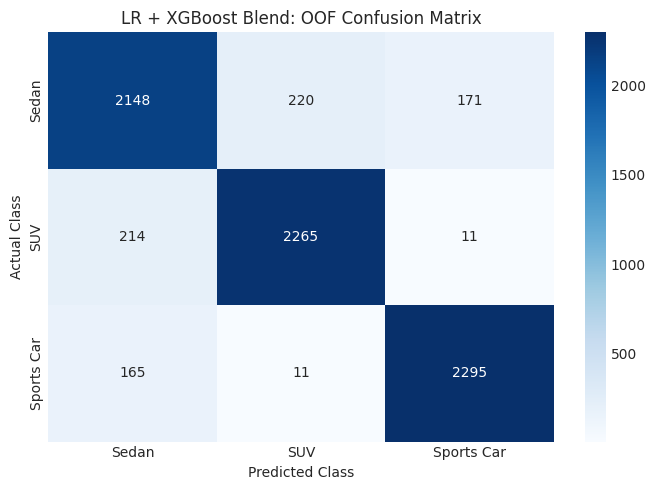


Saved final predictions:
  submission_tier3_xgb_blend.csv
  submission.csv


In [44]:

# ============================================================
# TIER 1, TIER 2, TIER 3: RAW-FEATURE MODEL COMPARISON
# Final model: Logistic Regression + XGBoost probability blend
# ============================================================

X_train_raw_mat = df_clean[feature_cols].values
y_train_vec = df_clean[target_col].values
X_test_raw_mat = df_test[feature_cols].values

n_splits = skf.n_splits
class_labels = np.sort(np.unique(y_train_vec))

# This dataset uses 0 = Sedan, 1 = SUV, 2 = Sports Car.
class_name_map = {
    0: "Sedan",
    1: "SUV",
    2: "Sports Car"
}
class_names = [
    class_name_map.get(c, str(c)) for c in class_labels
]

n_classes = len(class_labels)

# ------------------------------------------------------------
# TIER 1: SINGLE-FIT LOGISTIC REGRESSION
# ------------------------------------------------------------

scaler_tier1 = StandardScaler()
X_tr_sc_t1 = scaler_tier1.fit_transform(X_train_raw_mat)
X_te_sc_t1 = scaler_tier1.transform(X_test_raw_mat)

model_tier1 = LogisticRegression(
    C=0.10,
    max_iter=2000,
    solver="lbfgs",
    random_state=SEED
)
model_tier1.fit(X_tr_sc_t1, y_train_vec)

tier1_train_pred = model_tier1.predict(X_tr_sc_t1)
tier1_train_acc = accuracy_score(y_train_vec, tier1_train_pred)
tier1_train_err = 1.0 - tier1_train_acc

preds_tier1 = model_tier1.predict(X_te_sc_t1)

pd.DataFrame({
    id_col: df_test[id_col],
    target_col: preds_tier1
}).to_csv("submission_tier1_single_lr.csv", index=False)

print("=" * 75)
print("TIER 1: SINGLE-FIT LOGISTIC REGRESSION")
print(f"Training Accuracy : {tier1_train_acc * 100:.2f}%")
print(f"Training Error    : {tier1_train_err * 100:.2f}%")
print("Saved: submission_tier1_single_lr.csv")
print("=" * 75)


# ------------------------------------------------------------
# TIER 2: FIVE-FOLD LOGISTIC REGRESSION
# ------------------------------------------------------------

oof_lr_probs = np.zeros((len(X_train_raw_mat), n_classes))
test_lr_probs = np.zeros((len(X_test_raw_mat), n_classes))
lr_fold_train_accs = []

for tr_idx, va_idx in skf.split(X_train_raw_mat, y_train_vec):

    scaler = StandardScaler()

    X_tr_sc = scaler.fit_transform(X_train_raw_mat[tr_idx])
    X_va_sc = scaler.transform(X_train_raw_mat[va_idx])
    X_te_sc = scaler.transform(X_test_raw_mat)

    lr = LogisticRegression(
        C=0.10,
        max_iter=2000,
        solver="lbfgs",
        random_state=SEED
    )

    lr.fit(X_tr_sc, y_train_vec[tr_idx])

    # Training accuracy on this fold's training partition
    lr_fold_train_accs.append(
        accuracy_score(
            y_train_vec[tr_idx],
            lr.predict(X_tr_sc)
        )
    )

    # Validation predictions for rows excluded from this fold's training
    oof_lr_probs[va_idx] = lr.predict_proba(X_va_sc)

    # Average test probabilities across folds
    test_lr_probs += lr.predict_proba(X_te_sc) / n_splits


tier2_mean_train_acc = np.mean(lr_fold_train_accs)
tier2_val_pred = np.argmax(oof_lr_probs, axis=1)

tier2_val_acc = accuracy_score(y_train_vec, tier2_val_pred)
tier2_val_err = 1.0 - tier2_val_acc
tier2_mean_train_err = 1.0 - tier2_mean_train_acc

preds_tier2 = np.argmax(test_lr_probs, axis=1)

pd.DataFrame({
    id_col: df_test[id_col],
    target_col: preds_tier2
}).to_csv("submission_tier2_5fold_lr.csv", index=False)

print("\n" + "=" * 75)
print("TIER 2: FIVE-FOLD LOGISTIC REGRESSION ENSEMBLE")
print(f"Mean Fold Train Accuracy : {tier2_mean_train_acc * 100:.2f}%")
print(f"OOF Validation Accuracy  : {tier2_val_acc * 100:.2f}%")
print(f"OOF Validation Error     : {tier2_val_err * 100:.2f}%")
print(
    f"Train-Validation Gap     : "
    f"{(tier2_mean_train_acc - tier2_val_acc) * 100:+.2f} percentage points"
)
print("Saved: submission_tier2_5fold_lr.csv")
print("=" * 75)


# ------------------------------------------------------------
# TIER 3: LOGISTIC REGRESSION + RAW-FEATURE XGBOOST
# ------------------------------------------------------------

oof_xgb_probs = np.zeros((len(X_train_raw_mat), n_classes))
test_xgb_probs = np.zeros((len(X_test_raw_mat), n_classes))
xgb_fold_train_accs = []

for tr_idx, va_idx in skf.split(X_train_raw_mat, y_train_vec):

    X_tr = X_train_raw_mat[tr_idx]
    X_va = X_train_raw_mat[va_idx]

    xgb = XGBClassifier(
        n_estimators=350,
        learning_rate=0.04,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.7,
        reg_lambda=3.0,
        objective="multi:softprob",
        num_class=n_classes,
        eval_metric="mlogloss",
        random_state=SEED,
        n_jobs=-1,
        tree_method="hist"
    )

    xgb.fit(X_tr, y_train_vec[tr_idx])

    # Training accuracy for this fold
    xgb_fold_train_accs.append(
        accuracy_score(
            y_train_vec[tr_idx],
            xgb.predict(X_tr)
        )
    )

    # OOF probabilities for the held-out fold
    oof_xgb_probs[va_idx] = xgb.predict_proba(X_va)

    # Mean test probabilities across folds
    test_xgb_probs += (
        xgb.predict_proba(X_test_raw_mat) / n_splits
    )


xgb_mean_train_acc = np.mean(xgb_fold_train_accs)
xgb_oof_pred = np.argmax(oof_xgb_probs, axis=1)
xgb_val_acc = accuracy_score(y_train_vec, xgb_oof_pred)


# ------------------------------------------------------------
# SELECT THE BLEND WEIGHT USING OOF PREDICTIONS
# ------------------------------------------------------------

best_w = None
best_blend_acc = -1.0
blend_weight_results = []

for w in np.linspace(0.70, 0.98, 15):

    candidate_probs = (
        w * oof_lr_probs
        + (1.0 - w) * oof_xgb_probs
    )

    candidate_pred = np.argmax(candidate_probs, axis=1)
    candidate_acc = accuracy_score(y_train_vec, candidate_pred)

    blend_weight_results.append((w, candidate_acc))

    if candidate_acc > best_blend_acc:
        best_blend_acc = candidate_acc
        best_w = w


# ------------------------------------------------------------
# FINAL OOF METRICS FOR THE SELECTED BLEND
# ------------------------------------------------------------

oof_blend_probs = (
    best_w * oof_lr_probs
    + (1.0 - best_w) * oof_xgb_probs
)

blend_oof_pred = np.argmax(oof_blend_probs, axis=1)

blend_oof_acc = accuracy_score(y_train_vec, blend_oof_pred)
blend_oof_err = 1.0 - blend_oof_acc

lr_oof_acc = accuracy_score(
    y_train_vec,
    np.argmax(oof_lr_probs, axis=1)
)

xgb_oof_acc = accuracy_score(
    y_train_vec,
    np.argmax(oof_xgb_probs, axis=1)
)


# ------------------------------------------------------------
# PRINT VALIDATION METRICS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TIER 3: LOGISTIC REGRESSION + XGBOOST BLEND")
print("=" * 75)

print(f"LR OOF Accuracy       : {lr_oof_acc * 100:.2f}%")
print(f"XGBoost OOF Accuracy  : {xgb_oof_acc * 100:.2f}%")
print(f"Blend OOF Accuracy    : {blend_oof_acc * 100:.2f}%")
print(f"Blend OOF Error       : {blend_oof_err * 100:.2f}%")

print(
    f"Blend Weights         : "
    f"{best_w:.2f} Logistic Regression + "
    f"{1.0 - best_w:.2f} XGBoost"
)

print("\nClassification Report — OOF Predictions")
print(
    classification_report(
        y_train_vec,
        blend_oof_pred,
        labels=class_labels,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# CONFUSION MATRIX FOR THE BLEND
# Rows = actual classes; columns = predicted classes
# ------------------------------------------------------------

cm = confusion_matrix(
    y_train_vec,
    blend_oof_pred,
    labels=class_labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("LR + XGBoost Blend: OOF Confusion Matrix")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GENERATE FINAL TEST PREDICTIONS
# ------------------------------------------------------------

test_blend_probs = (
    best_w * test_lr_probs
    + (1.0 - best_w) * test_xgb_probs
)

preds_tier3 = np.argmax(test_blend_probs, axis=1)

pd.DataFrame({
    id_col: df_test[id_col],
    target_col: preds_tier3
}).to_csv("submission_tier3_xgb_blend.csv", index=False)

# This is the final submission file
pd.DataFrame({
    id_col: df_test[id_col],
    target_col: preds_tier3
}).to_csv("submission.csv", index=False)

print("\nSaved final predictions:")
print("  submission_tier3_xgb_blend.csv")
print("  submission.csv")
print("=" * 75)

### Additional Experiment: Engineered Features

An additional experiment was conducted to evaluate whether five domain-informed engineered features improved classification performance. The same feature-engineering procedure was applied to the training and test datasets, with feature-column consistency checks to prevent mismatches.

The engineered-feature models were compared with the raw-feature approach using cross-validation and competition evaluation. The raw-feature Logistic Regression and XGBoost blend was retained as the final model because it achieved the better competition score in the experiments. The engineered-feature pipeline is included for comparison.

In [42]:
# =========================================================================
# ENGINEERED PHYSICS PIPELINE — CORRECT TRAIN/TEST FEATURE CONSTRUCTION
# =========================================================================

# 1. Training features: 20 raw features + 5 engineered features
X_train_eng_df = engineer_physics_ratios(df_clean[feature_cols])

# 2. Test features: apply EXACTLY the same transformations
X_test_eng_df = engineer_physics_ratios(df_test[feature_cols])

# 3. Explicitly align test columns with training columns
X_test_eng_df = X_test_eng_df.reindex(columns=X_train_eng_df.columns)

# 4. Convert to NumPy arrays
X_train_eng_mat = X_train_eng_df.to_numpy(dtype=float)
X_test_eng_mat = X_test_eng_df.to_numpy(dtype=float)
y_train_eng = df_clean[target_col].to_numpy()

# 5. Sanity checks
assert X_train_eng_df.columns.equals(X_test_eng_df.columns)
assert X_train_eng_mat.shape[1] == 25
assert X_test_eng_mat.shape[1] == 25
assert len(X_train_eng_mat) == len(y_train_eng)
assert np.isfinite(X_train_eng_mat).all()
assert np.isfinite(X_test_eng_mat).all()

print("Training matrix:", X_train_eng_mat.shape)
print("Test matrix:", X_test_eng_mat.shape)
print("Feature columns aligned:", X_train_eng_df.columns.equals(X_test_eng_df.columns))
print("All feature values finite: True")

# 6. Run Optimized 5-Fold Stratified LR & XGBoost Blend on Engineered Features
oof_lr_eng_probs = np.zeros((len(X_train_eng_mat), 3))
test_lr_eng_probs = np.zeros((len(X_test_eng_mat), 3))

oof_xgb_eng_probs = np.zeros((len(X_train_eng_mat), 3))
test_xgb_eng_probs = np.zeros((len(X_test_eng_mat), 3))

for tr_idx, va_idx in skf.split(X_train_eng_mat, y_clean):
    scaler = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_train_eng_mat[tr_idx])
    X_va_sc = scaler.transform(X_train_eng_mat[va_idx])
    X_te_sc = scaler.transform(X_test_eng_mat)
    
    lr = LogisticRegression(C=0.10, max_iter=2000, solver='lbfgs', random_state=SEED)
    lr.fit(X_tr_sc, y_clean[tr_idx])
    oof_lr_eng_probs[va_idx] = lr.predict_proba(X_va_sc)
    test_lr_eng_probs += lr.predict_proba(X_te_sc) / 5.0
    
    X_tr_raw = X_train_eng_mat[tr_idx]
    X_va_raw = X_train_eng_mat[va_idx]
    
    xgb = XGBClassifier(
        n_estimators=350, learning_rate=0.04, max_depth=3,
        subsample=0.8, colsample_bytree=0.7, reg_lambda=3.0,
        objective='multi:softprob', num_class=3, eval_metric='mlogloss',
        random_state=SEED, n_jobs=-1, tree_method='hist'
    )
    xgb.fit(X_tr_raw, y_clean[tr_idx])
    oof_xgb_eng_probs[va_idx] = xgb.predict_proba(X_va_raw)
    test_xgb_eng_probs += xgb.predict_proba(X_test_eng_mat) / 5.0

val_acc_eng_lr = accuracy_score(y_clean, np.argmax(oof_lr_eng_probs, axis=1))
val_acc_eng_xgb = accuracy_score(y_clean, np.argmax(oof_xgb_eng_probs, axis=1))

blend_eng_oof = 0.90 * oof_lr_eng_probs + 0.10 * oof_xgb_eng_probs
val_acc_eng_blend = accuracy_score(y_clean, np.argmax(blend_eng_oof, axis=1))

test_eng_blend_probs = 0.90 * test_lr_eng_probs + 0.10 * test_xgb_eng_probs
preds_eng_final = np.argmax(test_eng_blend_probs, axis=1)

pd.DataFrame({id_col: df_test[id_col], target_col: preds_eng_final}).to_csv('submission_engineered_physics.csv', index=False)

print("--- ENGINEERED PHYSICS PIPELINE RESULTS ---")
print(f" > Logistic Regression OOF Val Acc : {val_acc_eng_lr * 100:.2f}%")
print(f" > XGBoost Standalone OOF Val Acc  : {val_acc_eng_xgb * 100:.2f}%")
print(f" > Blended Ensemble OOF Val Acc    : {val_acc_eng_blend * 100:.2f}%")
print(f" > Saved Specialized Predictions   : 'submission_engineered_physics.csv'")
print("=" * 80)

Training matrix: (7500, 25)
Test matrix: (2500, 25)
Feature columns aligned: True
All feature values finite: True
--- ENGINEERED PHYSICS PIPELINE RESULTS ---
 > Logistic Regression OOF Val Acc : 89.48%
 > XGBoost Standalone OOF Val Acc  : 88.60%
 > Blended Ensemble OOF Val Acc    : 89.40%
 > Saved Specialized Predictions   : 'submission_engineered_physics.csv'
